## 1. Brainstorm 

1. Individually, write down high-level steps on how you would explore and wrangle the data to produce this map. Do not code anything yet.

* Observe the format of the columns and check the coordinate reference system. 
* If the crs between the two datasets are different, then change them to the same extent.
* Create points from latitude and longitude.
* Add a world basemap

2. Discuss your high-level steps with your team. What do you see as potential challenges to implementing your plan?

3. As a team, select an initial plan for recreating this plot.

In [17]:
import pandas as pd

import os

from pandas.api.types import is_string_dtype, is_numeric_dtype

import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

raw_eqk = pd.read_csv('data/earthquake_data.csv')
fp = os.path.join('data','ne_110m_admin_0_countries','ne_110m_admin_0_countries.shp')

country = gpd.read_file(fp)

country.head()

,featurecla,scalerank,LABELRANK,SOVEREIGNT,SOV_A3,ADM0_DIF,LEVEL,TYPE,TLC,ADMIN,...,FCLASS_TR,FCLASS_ID,FCLASS_PL,FCLASS_GR,FCLASS_IT,FCLASS_NL,FCLASS_SE,FCLASS_BD,FCLASS_UA,geometry
0,Admin-0 country,1,6,Fiji,FJI,0,2,Sovereign country,1,Fiji,...,None,None,None,None,None,None,None,None,None,"MULTIPOLYGON (((180.00000 -16.06713, 180.00000..."
1,Admin-0 country,1,3,United Republic of Tanzania,TZA,0,2,Sovereign country,1,United Republic of Tanzania,...,None,None,None,None,None,None,None,None,None,"POLYGON ((33.90371 -0.95000, 34.07262 -1.05982..."
2,Admin-0 country,1,7,Western Sahara,SAH,0,2,Indeterminate,1,Western Sahara,...,Unrecognized,Unrecognized,Unrecognized,None,None,Unrecognized,None,None,None,"POLYGON ((-8.66559 27.65643, -8.66512 27.58948..."
3,Admin-0 country,1,2,Canada,CAN,0,2,Sovereign country,1,Canada,...,None,None,None,None,None,None,None,None,None,"MULTIPOLYGON (((-122.84000 49.00000, -122.9742..."
4,Admin-0 country,1,2,United States of America,US1,1,2,Country,1,United States of America,...,None,None,None,None,None,None,None,None,None,"MULTIPOLYGON (((-122.84000 49.00000, -120.0000..."


In [8]:
raw_eqk.head()

,time,latitude,longitude,depth,mag,id,place,type
0,2014-01-31 23:53:37.000,60.252000,-152.7081,90.20,1.10,ak11155107,"26km S of Redoubt Volcano, Alaska",earthquake
1,2014-01-31 23:48:35.452,37.070300,-115.1309,0.00,1.33,nn00436847,"32km S of Alamo, Nevada",earthquake
2,2014-01-31 23:47:24.000,64.671700,-149.2528,7.10,1.30,ak11151142,"12km NNW of North Nenana, Alaska",earthquake
3,2014-01-31 23:30:54.000,63.188700,-148.9575,96.50,0.80,ak11151135,"22km S of Cantwell, Alaska",earthquake
4,2014-01-31 23:30:52.210,32.616833,-115.6925,10.59,1.34,ci37171541,"10km WNW of Progreso, Mexico",earthquake


In [25]:
raw_eqk['time'] = pd.to_datetime(raw_eqk['time'])
raw_eqk['year'] = raw_eqk['time'].dt.year

filter_eqk = raw_eqk[(raw_eqk['year'] == 2014) & (raw_eqk['mag'] >= 6.5)]

In [10]:
country.crs

<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [26]:
points = gpd.points_from_xy(filter_eqk['longitude'],
                            filter_eqk['latitude'])

print(points)

<GeometryArray>
[ <POINT (167.249 -13.863)>,   <POINT (-58.927 14.668)>,
    <POINT (82.586 35.905)>,  <POINT (167.372 -15.069)>,
 <POINT (-177.881 -32.908)>,  <POINT (-70.702 -19.981)>,
  <POINT (-125.134 40.829)>,   <POINT (127.367 27.431)>,
  <POINT (-127.732 49.639)>,   <POINT (155.024 -6.755)>,
   <POINT (155.087 -6.656)>,  <POINT (-100.972 17.397)>,
    <POINT (8.722 -53.497)>,  <POINT (162.052 -11.128)>,
  <POINT (162.051 -11.463)>,   <POINT (162.148 -11.27)>,
   <POINT (-85.878 11.642)>,    <POINT (154.95 -6.788)>,
   <POINT (155.048 -6.586)>,  <POINT (-70.493 -20.571)>,
  <POINT (-70.576 -20.311)>,  <POINT (-70.946 -19.893)>,
   <POINT (-70.769 -19.61)>,    <POINT (25.389 40.289)>,
     <POINT (-82.304 7.21)>,    <POINT (-114.8 -49.94)>,
  <POINT (179.086 -24.611)>,  <POINT (170.355 -21.454)>,
  <POINT (-175.51 -14.983)>,   <POINT (-28.367 -55.47)>,
   <POINT (178.735 51.849)>, <POINT (-177.607 -29.941)>,
 <POINT (-177.516 -29.938)>, <POINT (-177.725 -29.977)>,
   <POINT (91.0

In [27]:
eqk = gpd.GeoDataFrame(filter_eqk,
                       geometry = points,
                       crs = 'EPSG:4326')

eqk.geometry

9062       POINT (167.24900 -13.86330)
12142       POINT (-58.92720 14.66820)
14025        POINT (82.58640 35.90530)
15979      POINT (167.37210 -15.06910)
17606     POINT (-177.88060 -32.90760)
22968      POINT (-70.70220 -19.98070)
24887      POINT (-125.13380 40.82870)
26972       POINT (127.36740 27.43120)
29890      POINT (-127.73160 49.63880)
31496       POINT (155.02410 -6.75470)
31670       POINT (155.08690 -6.65580)
31850      POINT (-100.97230 17.39700)
32964        POINT (8.72200 -53.49670)
33523      POINT (162.05200 -11.12840)
33537      POINT (162.05110 -11.46330)
33808      POINT (162.14810 -11.27010)
34096       POINT (-85.87790 11.64200)
34302       POINT (154.95020 -6.78780)
34318       POINT (155.04850 -6.58580)
36918      POINT (-70.49310 -20.57090)
36929      POINT (-70.57560 -20.31130)
37367      POINT (-70.94550 -19.89270)
37371      POINT (-70.76910 -19.60970)
39915        POINT (25.38890 40.28930)
43290        POINT (-82.30450 7.20960)
43450     POINT (-114.799

<Axes: >

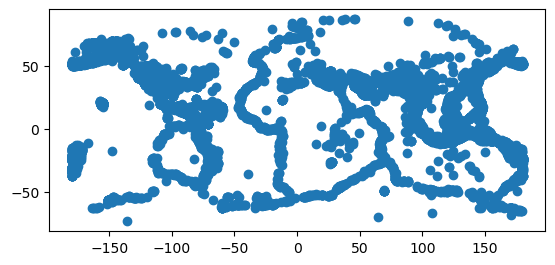

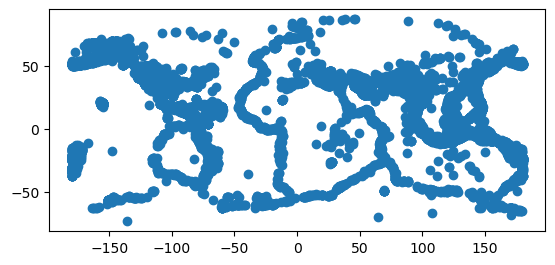

In [15]:
eqk.plot()

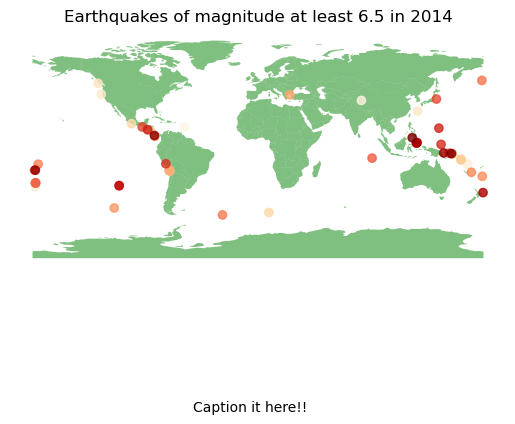

In [41]:
fig, ax = plt.subplots()

country.plot(ax=ax, # Add plot to specific axes
             alpha = 0.5, # Control frequency
             color = 'green') # Update point color

eqk.plot(ax=ax, # Add plot to specific axes
         alpha = 0.8, # Control frequency
         c = "mag",
         cmap = "OrRd",
         markersize=60,
         edgecolor='black',
        linewidth=0.4,
         legend=True,
         legend_kwds={'label': 'Magnitude', 'orientation': 'horizontal', 'shrink': 0.5, 'pad': 0.02}) # Update point color

plt.figtext(0.5, -0.05, 'Caption it here!!', horizontalalignment = 'center', wrap = True)
ax.set_title('Earthquakes of magnitude at least 6.5 in 2014')
ax.set_axis_off()

plt.show()